In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split

In [5]:
url = "https://gist.githubusercontent.com/SINENSIA/b94e8ba33b7af499b7ddcaad312f7010/raw/c154fcbb099f0e542de8ea68b3821a0a2f7aeef2/tmdb_5000_movies.csv"
df = pd.read_csv(url)


df = df[['budget', 'revenue', 'runtime', 'vote_average', 'popularity']].dropna()
df = df[(df['budget'] > 0) & (df['revenue'] > 0)]

df['is_superhit'] = (df['revenue'] > df['budget'] * 3).astype(int)

print(f"Размер очищенного датасета: {df.shape}")
df.head()

Размер очищенного датасета: (3229, 6)


,budget,revenue,runtime,vote_average,popularity,is_superhit
0,237000000,2787965087,162.0,7.2,150.437577,1
1,300000000,961000000,169.0,6.9,139.082615,1
2,245000000,880674609,148.0,6.3,107.376788,1
3,250000000,1084939099,165.0,7.6,112.312950,1
4,260000000,284139100,132.0,6.1,43.926995,0


In [14]:
X = df.drop('is_superhit', axis=1)
y = df['is_superhit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

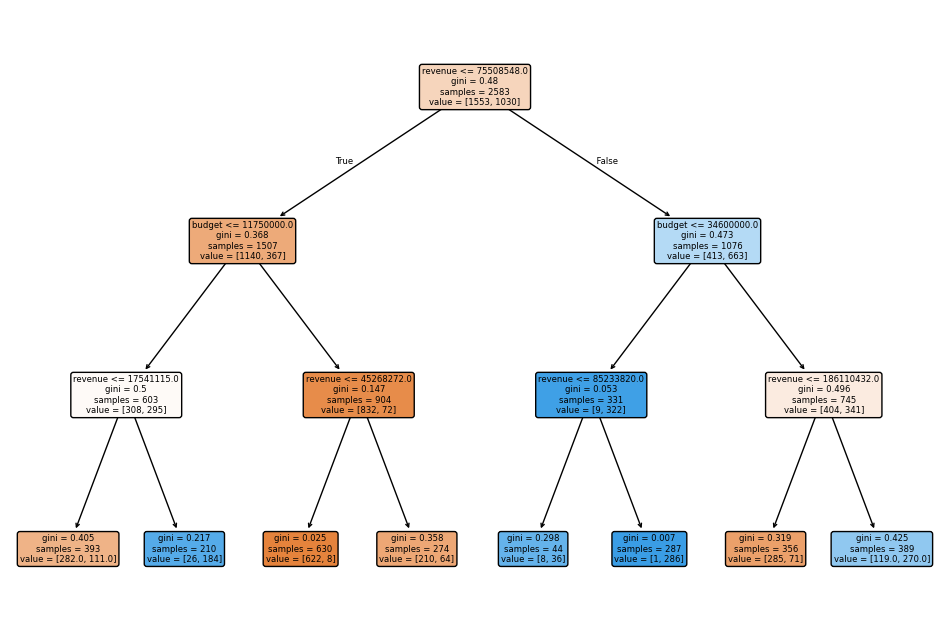

In [19]:
model = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
model.fit(X_train, y_train)

plt.figure(figsize=(12, 8))

plot_tree(model, feature_names=df.columns.tolist(),filled=True, rounded=True)
plt.show()

In [22]:
prob_tree1 = 0.51
prob_tree2 = 0.51
prob_tree3 = 0.02

pred_tree1 = 1 if prob_tree1 > 0.5 else 0
pred_tree2 = 1 if prob_tree2 > 0.5 else 0
pred_tree3 = 1 if prob_tree3 > 0.5 else 0

votes = pred_tree1 + pred_tree2 + pred_tree3
total_trees = 3

if votes > total_trees / 2:
    result = 1
else: 
    result = 0

print(f"Final hard voting prediction: {result}")

Final hard voting prediction: 1


In [23]:
prob_tree1 = 0.51
prob_tree2 = 0.51
prob_tree3 = 0.02
n_trees = 3

avg_prob = (prob_tree1 + prob_tree2 + prob_tree3) / n_trees

if avg_prob > 0.5:
    result = 1
else: 
    result = 0

print(f"Final soft voting prediction: {result}")

Final soft voting prediction: 0


In [30]:
X = df[['budget']]
y = df['revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

rf = RandomForestRegressor(n_estimators=300, max_features='sqrt', random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

gb = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

/home/michael/.local/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
/home/michael/.local/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/home/michael/.local/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


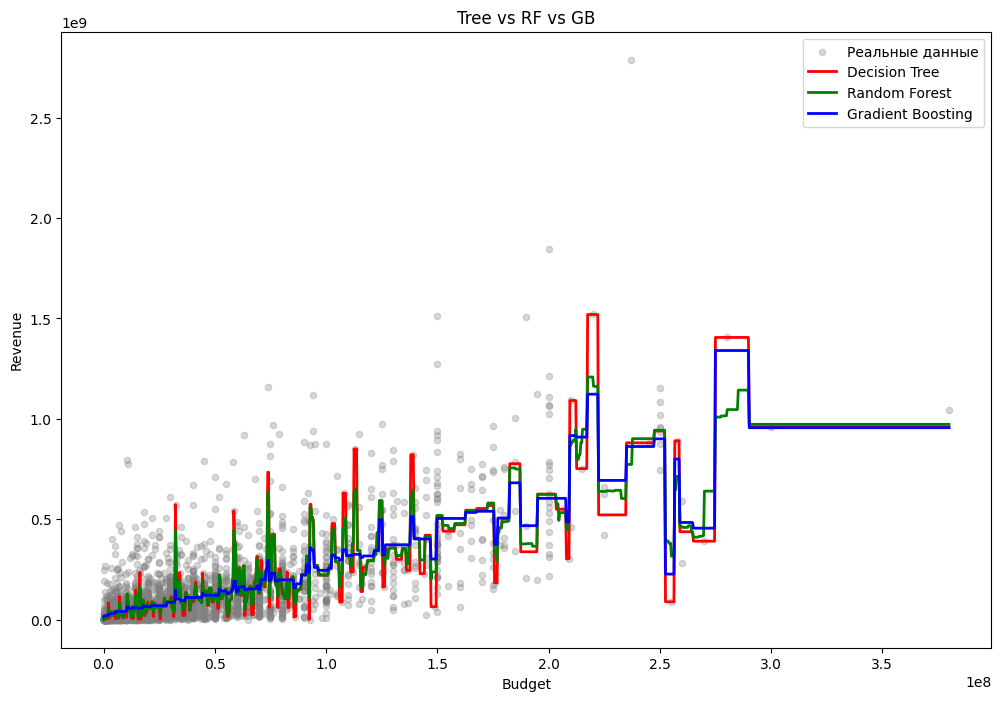

In [34]:
budget_range = np.linspace(X.min(), X.max(), 1000).reshape(-1, 1)

plt.figure(figsize=(12, 8))
plt.scatter(X, y, alpha=0.3, s=20, color='gray', label='Реальные данные')
plt.plot(budget_range, tree.predict(budget_range), 'r-', linewidth=2, label='Decision Tree')
plt.plot(budget_range, rf.predict(budget_range), 'g-', linewidth=2, label='Random Forest')
plt.plot(budget_range, gb.predict(budget_range), 'b-', linewidth=2, label='Gradient Boosting')

plt.xlabel('Budget')
plt.ylabel('Revenue')
plt.title('Tree vs RF vs GB')
plt.legend()